# zf1 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst
from tqdm.notebook import tqdm

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830, SR860
from qcodes.instrument_drivers.Keithley import Keithley2400
from qcodes.instrument_drivers.american_magnetics import AMIModel430

import sweep

from hera.analysis import GateCalibration, field_invB

from sharpelab_nb.constants import TOPLOADER
from sharpelab_nb.thermometry import temperature_from_logfile
from sharpelab_nb.drivers import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\toploader\\measurements\\aaron\\20260624-3-zf1'

# Connect Instruments

## Magnet

In [3]:
MAGNET_ADDR = "TCPIP0::192.168.0.101::7180::SOCKET"  # <-- verify address
magnet = AMIModel430("magnet", address=MAGNET_ADDR)
# Field in Tesla; magnet.field() is the MEASURED readback (coil constant
# 0.116783 T/A is configured on the unit). magnet.field(target) BLOCKS until
# the supply reports holding; a kernel interrupt does NOT stop the ramp.
magnet.field()

Connected to: AMERICAN MAGNETICS INC. 430 (serial:430-11-044, firmware:2.65) in 0.99s


5.52e-06

## Thermometry (file-based) + sample heater

Kernel temperature reads are **file-based**, not GPIB — the AVS bridge workers
own the bridges and write the logfiles. `temperature` is the loaded probe's
mixing chamber; the logfile path is **probe-dependent** (Probe1 = straight,
Probe2 = rotator). The sample heater is an **open-loop** Keithley voltage
source — set `heater.volt`, settle, then read T back from `temperature()`.

In [4]:
# Probe MC (sample T) — point at the LOADED probe (Probe1 straight / Probe2 rotator)
temperature = temperature_from_logfile(
    "T", r"C:\Users\toploader\temperature_logs\Probe2_MixingCh_low.txt")  # <-- verify probe
fridge_temperature = temperature_from_logfile("T_fridge", TOPLOADER.temp_logfiles["T_fridge"])
mag_temperature = temperature_from_logfile("T_magnet", TOPLOADER.temp_logfiles["T_magnet"])
print("probe MC:", temperature(), "K")

# Sample-stage heater — open-loop voltage drive (V->T is per-cooldown; device card)
heater = Keithley2400("heater", "GPIB4::12::INSTR")  # <-- verify address
heater.mode.set("VOLT")
heater.volt.step = 0.005

probe MC: 0.03393 K
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1299232, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.10s


## Lock-ins

In [5]:
sr830_1 = SR830("sr830_1", "GPIB0::8::INSTR")  # <-- verify — current channel (Ithaco 1211 preamp output)
sr830_2 = SR830("sr830_2", "GPIB0::9::INSTR")  # <-- verify
sr830_3 = SR830("sr830_3", "GPIB0::4::INSTR")  # <-- verify
sr830_4 = SR830("sr830_4", "GPIB0::1::INSTR")  # <-- verify
sr830_5 = SR830("sr830_5", "GPIB0::5::INSTR")  # <-- verify
sr830_6 = SR830("sr830_6", "GPIB0::6::INSTR")  # <-- verify
sr830_7 = SR830("sr830_7", "GPIB0::7::INSTR")  # <-- verify
# sr830_8 = SR860("sr830_8", "TCPIP::192.168.0.107::inst0::INSTR")  # <-- verify — SR860; enable if used

C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n45469, firmware:ver1.07) in 0.13s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45595, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45471, firmware:ver1.07) in 0.11s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


Connected to: Stanford_Research_Systems SR830 (serial:s/n43722, firmware:ver1.07) in 0.16s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45470, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n43721, firmware:ver1.07) in 0.08s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_5 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_5 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_6 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n41621, firmware:ver1.07) in 0.10s


## Keithleys (gates)

In [6]:
# Gate Keithleys are role-named on this rig (k_tg/k_bg drive top/back gates),
# so recipes' k_tg / k_bg resolve directly. The third Keithley's role is
# per-insert (Si gate, or a probe-specific winding). Defaults: rangev 21,
# rangei 1uA, compliance 10 nA / 20 V, step 5 mV.
def _setup_k2400(k):
    # k.mode.set("VOLT")
    # k.rangev.set(21)
    # k.rangei.set(1e-6)
    # k.compliancev.set(20)
    # k.compliancei.set(1e-8)
    k.volt.step = 0.005
    return k

k_tg  = _setup_k2400(Keithley2400("k_tg",  "GPIB4::9::INSTR"))   # <-- verify — top gate
k_bg  = _setup_k2400(Keithley2400("k_bg",  "GPIB4::10::INSTR"))  # <-- verify — back gate
k_tg2 = _setup_k2400(Keithley2400("k_tg2", "GPIB4::11::INSTR"))  # <-- verify — third Keithley (per-insert role)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028439, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028442, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.04s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028489, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s


## DC205 (DC current bias)

On the toploader, gates are Keithleys; the DC205s are **DC current-bias**
sources (through a 100 MΩ series resistor — see the device card). Set
`volt -> 0` before reconfiguring or ending a measurement.

In [7]:
dc205_1 = SRS_DC205("dc205_1", "ASRL6::INSTR")  # <-- verify address — DC current bias
dc205_1.volt = dc205_1.voltage
dc205_1.volt.step = 0.005

dc205_3 = SRS_DC205("dc205_3", "ASRL7::INSTR")  # <-- verify address — second DC205
dc205_3.volt = dc205_3.voltage
dc205_3.volt.step = 0.005

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500516, firmware:ver1.80) in 0.02s
Connected to: Stanford_Research_Systems DC205 (serial:s/n20500513, firmware:ver1.80) in 0.04s


# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [8]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`.
TG_MIN, TG_MAX = -7.0, +6.0   # top gate (k_tg), V    # <-- validate
BG_MIN, BG_MAX = -4.0, +4.2   # back gate (k_bg), V    # <-- validate
k_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter, so
# this validator rejects magnet.field(target) with |B| > cap before any
# hardware traffic. Driver backstop: |B| <= COIL? x current_limit (~9 T) on the
# AMI430 unit.
B_SESSION_CAP = 0.1  # Tesla    # <-- validate (session cap from card/brief)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Sample-heater ceiling for sustained runs (V, not T — open-loop drive).
HEATER_V_MAX = 6.5  # V    # <-- validate
heater.volt.vals = validators.Numbers(0, HEATER_V_MAX)

# DC current-bias range (SRS DC205 hardware: +/-15 V -> +/-150 nA at 100 MOhm).
dc205_1.volt.vals = validators.Numbers(-15, 15)

# Helpers

In [9]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)


def interruptable_sleep(total: float, chunk: float = 0.1):
    """
    Sleep for `total` seconds in chunks of `chunk` seconds, breakable by a
    kernel interrupt and showing a tqdm progress bar rounded to 0.1 s. Use
    this for any wait longer than a few seconds (thermalization, base-T
    recovery, magnet settle) so the operator's interrupt lands cleanly.
    """
    bar_fmt = "{l_bar}{bar}| {n:.1f}/{total:.1f}s [{postfix}]"
    with tqdm(total=total, desc="Sleeping", unit="s", bar_format=bar_fmt) as pbar:
        end = time.monotonic() + total
        while True:
            remaining = max(0.0, end - time.monotonic())
            if remaining <= 0:
                pbar.update(round(pbar.total - pbar.n, 1))
                pbar.set_postfix_str("0.0s left")
                break
            step = min(chunk, remaining)
            time.sleep(step)
            pbar.update(round(step, 1))
            pbar.n = round(pbar.n, 1)
            pbar.set_postfix_str(f"{round(end - time.monotonic(), 1):.1f}s left")
            pbar.refresh()

In [10]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [11]:
# slot: meas-config — channel/contact assignments + gains from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Toploader contacts are wired
# DIRECT (no QSwitch) — name the contact pair per channel. Always set 'comment'
# per run — structured, current, no inherited text.
meas_config = {
    "sr1": "5-4",     "sr1_gain": -1e6,   # current channel (Ithaco 1211)    # <-- validate
    "sr2": "5-4",     "sr2_gain": 1e2,    # 2T    # <-- validate
    "sr3": "30-31",   "sr3_gain": 1e2,    # 4T longitudinal    # <-- validate
    "bias_resistor": 1e8,
    "bias_voltage_1": sr830_1.amplitude(),
    "lockin_freq_1": sr830_1.frequency(),
    "comment": "zf1 bottom device — 2026-06-24",
}

# HERA — session start (zf1, 2026-06-24)

## HERA — Gate C: gate-current sanity / device liveness (gate-current-sanity-check)

**Why now.** Bring-up is green: setup ran clean in this kernel, magnet at ~5.5 µT (≈0), probe MC 33.9 mK with the Probe2 logfile *advancing* (not the frozen-bridge case the rig card flags), and SAFETIES committed exactly to the device-card limits (TG (−7,+6), BG (−4,+4.2), |B|≤100 mT). The one open VERIFY item is contact wiring / a live 4-terminal Rxx — this cell establishes it. Per `sc-characterization` Step-1 prerequisites, this liveness pass gates everything downstream, so it runs before the pristine-field map.

**What runs (Cell A).** Four legs — k_tg→+6, k_tg→−7, k_bg→+4.2, k_bg→−4 — each from 0 with the other gate parked at 0, 251 pts, delay 1 s, gate-current readback at nplci=10 (pA floor). Each leg is its own run/slug. The card limits sit well inside the geometry ceiling (~±11.8 V TG, ±10 V BG), so sweeping to them is safe.

**Watch live, per leg:**
- `sr830_3.X` (4T Rxx, 30‑31): nonzero, smoothly varying ⇒ device alive on the 4-terminal channel. `sr830_1.X` (current, 5‑4) and `sr830_2.X` (2T, 5‑4): sensible, not flat-zero or all-equal (the grounded-device tell).
- swept gate `*.curr`: stays in pA on the capacitive charging slope to the limit ⇒ clean.
- parked gate `*.curr`: at the readback floor ⇒ no cross-gate path.

A gross turn-up off the charging slope = a leak → **Kernel Interrupt** (the `finally` parks the swept gate), then stop and report — skip Cell B.

**Cost:** ~20–25 min (≈5–6 min/leg at nplci=10 + ramp-backs); first real timing calibration for this dir. **Handshake:** you run Cell A, watch the plots, report per-leg; I won't propose the map until you do. Run **Cell B** (reset nplci → 1) only if every leg looked clean.

*(Note on mode: the brief's Autonomy section sets E1 this round on your "go for autonomy" once VERIFY/SAFETIES are green — they now are — while the Session-arc line reads "E0 throughout." This liveness check is human-run either way; flagging the wording mismatch for you to resolve before I'd execute anything autonomously.)*


T probe MC  : 0.03415 K   (expect base, ~0.03)
B field     : 9.935e-06 T   (expect ~0)


k_tg.volt   : 0.0 V


k_bg.volt   : 0.0 V
TG validator: <Numbers -7.0<=v<=6.0>   BG validator: <Numbers -4.0<=v<=4.2>


2026-06-24 15:57:51,399 [INFO] Ramping k_tg_volt: 0.0 -> 0


2026-06-24 15:57:51,914 [INFO] Ramping k_bg_volt: 0.0 -> 0


2026-06-24 15:57:51,926 [INFO] Starting sweep with ID 0


2026-06-24 15:57:51,926 [INFO] Minimum duration 0h 4m 11s


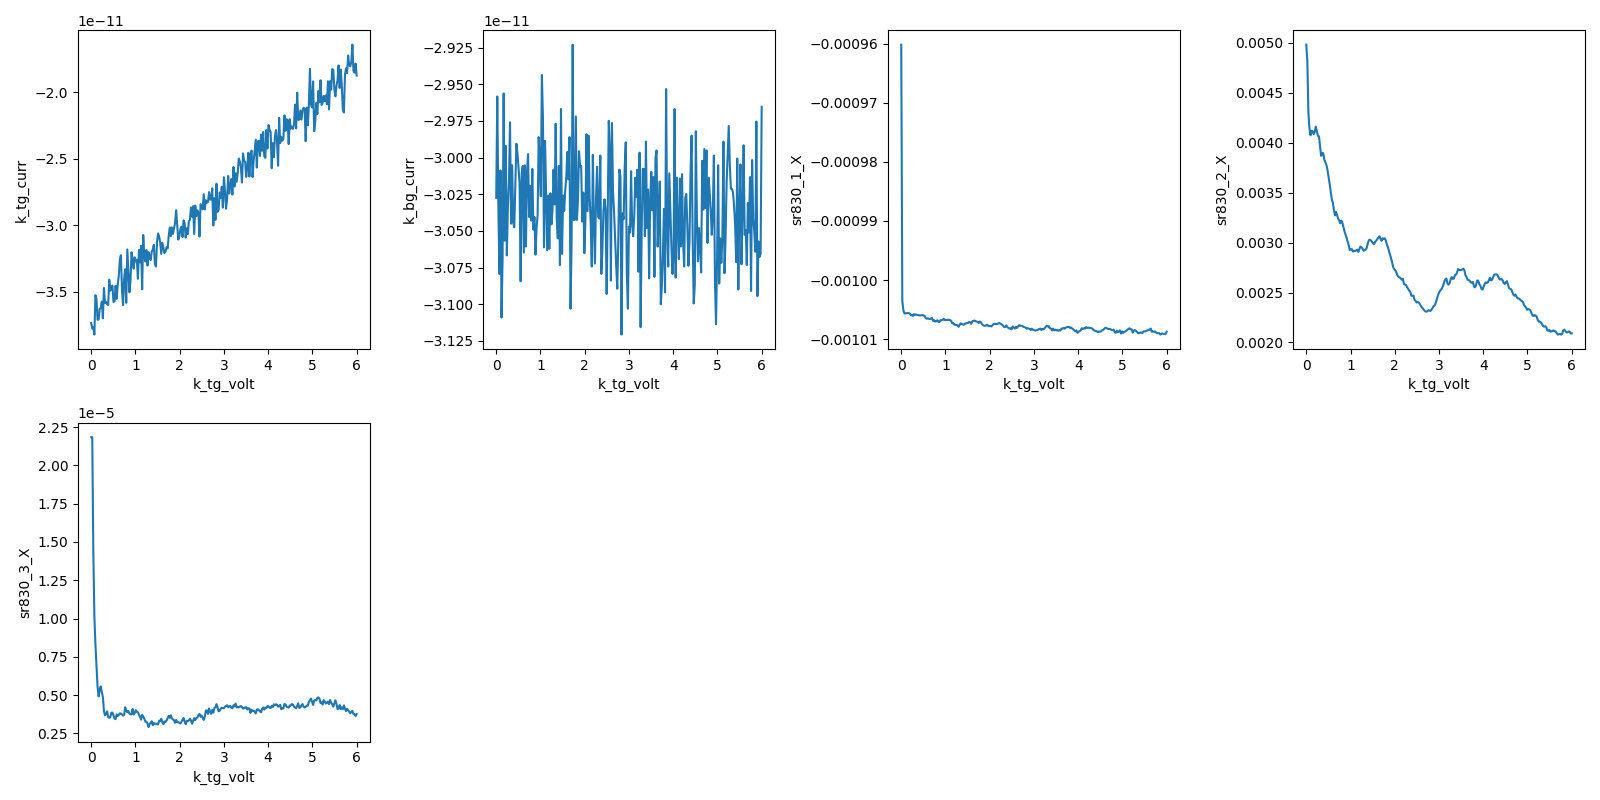

2026-06-24 16:06:30,877 [INFO] Completed in 0h 8m 38s


2026-06-24 16:06:30,878 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-3-zf1\data\0\data.tsv.gz


2026-06-24 16:06:31,389 [INFO] Ramping k_tg_volt: 6.0 -> 0


2026-06-24 16:06:39,458 [INFO] Ramping k_tg_volt: 0.0 -> 0


2026-06-24 16:06:39,978 [INFO] Ramping k_bg_volt: 0.0 -> 0


2026-06-24 16:06:39,986 [INFO] Starting sweep with ID 1


2026-06-24 16:06:39,987 [INFO] Minimum duration 0h 4m 11s


In [ ]:
# === Gate C liveness / gross-safety: gate-current-sanity-check ===
# Sweep each active gate 0 -> each device-card limit, the other parked at 0,
# watching gate current at pA resolution (nplci=10). Read the live plots per leg:
#   sr830_3.X  (4T Rxx, contacts 30-31): nonzero, smoothly varying -> device alive
#   sr830_1.X  (current ch, 5-4) and sr830_2.X (2T, 5-4): sensible, not flat
#   swept gate *.curr : pA, riding the capacitive charging slope -> safe
#   parked gate *.curr: at the readback floor -> no cross-gate path
# A gross turn-up off the charging slope = LEAK -> Kernel Interrupt (the finally
# parks the swept gate); stop and report, do NOT run Cell B.

# --- preconditions (this cell assumes these, does not set them) ---
print("T probe MC  :", temperature(), "K   (expect base, ~0.03)")
print("B field     :", magnet.field(), "T   (expect ~0)")
print("k_tg.volt   :", k_tg.volt(), "V")
print("k_bg.volt   :", k_bg.volt(), "V")
print("TG validator:", k_tg.volt.vals, "  BG validator:", k_bg.volt.vals)
assert temperature() < 0.060, "probe MC not at base T"
assert abs(magnet.field()) < 0.005, "field not near zero"

# one leg per gate per polarity, (gate, endpoint = card limit from the SAFETIES slot)
legs = [
    (k_tg, TG_MAX), (k_tg, TG_MIN),
    (k_bg, BG_MAX), (k_bg, BG_MIN),
]
n_pts   = 251
delay   = 1            # s
lockins = [sr830_1, sr830_2, sr830_3]   # mc: sr1(I,5-4), sr2(2T,5-4), sr3(4T,30-31)

# pA-floor readback on the gate-current channels; Cell B resets to 1.
k_tg.nplci(10)
k_bg.nplci(10)

# AC sense drive ~1 nA: 0.1 V across the 100 MOhm bias resistor (device card).
# Set explicitly so we don't inherit a residual amplitude that starves the X read.
sr830_1.amplitude(0.1)

for gate, v_endpoint in legs:
    s = sweep.AsyncStation(meas_config)
    s.add_comment('gate-current-sanity-check')
    s.add_comment(f'gate: {gate.name}')
    s.add_comment(f'leg: 0 -> {v_endpoint:+g} V (card limit)')

    # park both gates at 0 (the swept one starts from 0)
    s.ramp(k_tg.volt, 0)
    s.ramp(k_bg.volt, 0)

    xp = gate.volt
    s.fp(temperature)
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    s.plot(xp, k_tg.curr)
    s.plot(xp, k_bg.curr)
    for lia in lockins:
        s.fp(lia.X).fp(lia.P)
        s.plot(xp, lia.X)

    try:
        s.sweep(gate.volt, np.linspace(0, v_endpoint, n_pts), delay=delay)
    finally:
        s.ramp(gate.volt, 0)


### Cell B — reset gate-current nplci (run only if every leg looked safe)

Resets the gate-current channels back to nplci=1 and prints the live validators to confirm theyre intact. If any leg leaked, do not run this — stop and report.


In [14]:
# === Reset gate-current nplci (run ONLY if every leg looked safe) ===
# Undo Cell A's nplci bump; print the live validators to confirm they're intact.
k_tg.nplci(1)
k_bg.nplci(1)
print("k_tg.volt validator:", k_tg.volt.vals)
print("k_bg.volt validator:", k_bg.volt.vals)


k_tg.volt validator: <Numbers -7.0<=v<=6.0>
k_bg.volt validator: <Numbers -4.0<=v<=4.2>


## HERA — fix stale I_bias + lock-in diagnostics

The meas_config (cell 21) captured `bias_voltage_1 = sr830_1.amplitude()` *before* the AC drive was set, so metadata recorded I_bias = 40 pA (residual ~4 mV) while the true device current is ~1 nA. This refreshes the config to I_bias = 1 nA and prints lock-in TC / sensitivity to size the upcoming gate map. (Gate C passed clean on all 4 legs.)

In [13]:
# === Fix stale I_bias in meas_config (drive amplitude set AFTER config cell) ===
# meas_config['bias_voltage_1'] was captured before the AC drive was set, so
# metadata carried I_bias = residual ~4 mV / 100 MOhm = 40 pA, while the true
# device current is ~1 nA (0.1 V across 100 MOhm). Set the drive explicitly,
# then refresh the config so every downstream run records the correct I_bias.
sr830_1.amplitude(0.1)           # 0.1 V -> 1 nA through the 100 MOhm bias resistor
meas_config["bias_voltage_1"] = sr830_1.amplitude()
meas_config["lockin_freq_1"]  = sr830_1.frequency()

I_bias = meas_config["bias_voltage_1"] / meas_config["bias_resistor"]
print("drive amplitude :", sr830_1.amplitude(), "V")
print("bias_resistor   :", meas_config["bias_resistor"], "Ohm")
print("=> I_bias        :", I_bias, "A   (expect ~1e-9)")
assert abs(I_bias - 1e-9) < 2e-10, "I_bias not ~1 nA -- check drive amplitude"

# --- lock-in diagnostics (to size the gate-map fast_delay + sensitivity) ---
for nm, lia in [("sr830_1", sr830_1), ("sr830_2", sr830_2), ("sr830_3", sr830_3)]:
    print(f"{nm}: TC={lia.time_constant()} s  sens={lia.sensitivity()} V  "
          f"freq={lia.frequency()} Hz  phase={lia.phase()} deg")
print("gates now: k_tg.volt", k_tg.volt(), " k_bg.volt", k_bg.volt())
print("field:", magnet.field(), "T")


drive amplitude : 0.1 V
bias_resistor   : 100000000.0 Ohm
=> I_bias        : 1e-09 A   (expect ~1e-9)
sr830_1: TC=0.3 s  sens=0.001 V  freq=7.777 Hz  phase=0.0 deg
sr830_2: TC=0.3 s  sens=0.1 V  freq=7.777 Hz  phase=0.0 deg
sr830_3: TC=0.3 s  sens=2e-05 V  freq=7.777 Hz  phase=0.0 deg


gates now: k_tg.volt 0.0  k_bg.volt 0.0
field: -5.2547e-05 T


## HERA — Step 1: pristine-field gate map (overview + cap-ratio)

**sc-characterization Step 1**, taken **before energising the magnet** (field-history protocol — the map must be pristine; magnet at −53 µT, untouched). Axis-aligned raw (V_tg, V_bg) megasweep over the **full validator box** — TG [−7,+6] × BG [−4,+4.2] — doing double duty: a coarse overview to spot low-Rxx candidate regions, and the CNP-ridge slope for **cap-ratio calibration** (device-card geometry is only a prior).

**Grid:** 81 (TG slow) × 69 (BG fast) = 5589 pts, slow_delay 1.5 s, fast_delay 0.5 s (~1.6×TC; TC=0.3 s). Steps ≈ 0.16 V (TG) / 0.12 V (BG) — coarse but enough to locate the CNP ridge and rough low-R structure; the tight nD-map zooms candidates later. 4T sens raised to 5 mV (resolves R up to ~50 kΩ; clips only at a gapped CNP, where the ridge is still locatable). I_bias now correct at 1 nA.

**Cost ≈ 1.9 h** (from measured ~1.2 s/pt). **Checkpoints:** I'll read first rows (leakage <1 nA on both gates, 4T not railed everywhere, current flat ~1 nA), then periodically. Abort lever = nb-collab interrupt. Running it autonomously now (E1).

T        : 0.03407 K  (expect base ~0.03)
B        : 6.62e-07 T  (pristine - controller NOT ramped here)
gates    : 0.0 0.0 V
I_bias   : 1e-09 A


2026-06-24 17:01:45,813 [INFO] Ramping k_tg_volt: 0.0 -> -7.0


2026-06-24 17:01:54,801 [INFO] Ramping k_bg_volt: 0.0 -> -4.0


Sleeping:   0%|          | 0.0/10.0s []

2026-06-24 17:02:09,925 [INFO] Starting megasweep with ID 4


2026-06-24 17:02:09,926 [INFO] Minimum duration 0h 48m 36s


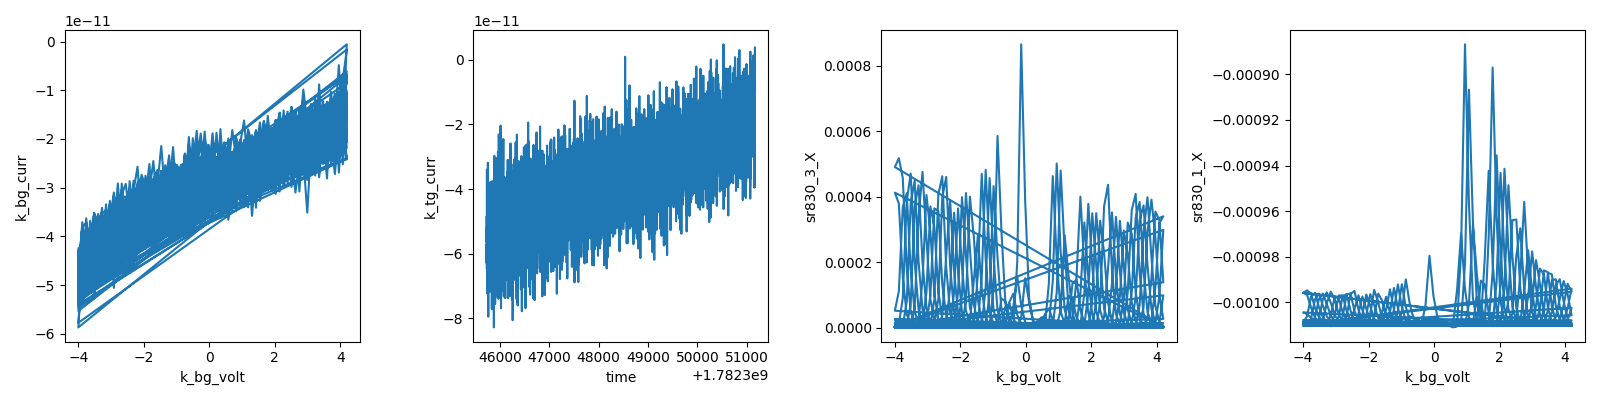

2026-06-24 18:32:48,041 [INFO] Completed in 1h 30m 37s


2026-06-24 18:32:48,041 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-3-zf1\data\4\data.tsv.gz


2026-06-24 18:32:48,103 [INFO] Ramping k_tg_volt: 6.0 -> 0


2026-06-24 18:32:55,711 [INFO] Ramping k_bg_volt: 4.2 -> 0


In [15]:
# === Step 1: pristine-field gate map (axis-aligned raw V_tg / V_bg) ===
# sc-characterization Step 1: Rxx(V_tg, V_bg) at PRISTINE field, BEFORE energising
# the magnet. Double duty -> (a) coarse overview to locate low-Rxx candidate
# regions, (b) CNP-ridge slope for cap-ratio calibration (geometry is a prior).
# Coarse survey over the FULL validator box; zoom into candidates afterward.

# --- preconditions (this cell assumes; it does NOT touch the field) ---
print("T        :", temperature(), "K  (expect base ~0.03)")
print("B        :", magnet.field(), "T  (pristine - controller NOT ramped here)")
print("gates    :", k_tg.volt(), k_bg.volt(), "V")
print("I_bias   :", meas_config["bias_voltage_1"] / meas_config["bias_resistor"], "A")
assert temperature() < 0.060, "not at base T"
assert abs(magnet.field()) < 0.005, "field not near zero - map must be pristine-field"

# 4T channel sensitivity: resolve up to ~50 kOhm (sens >= R_max * I_ac * G;
# 5 mV / 100 gain / 1 nA = 50 kOhm). Clips only at a strongly gapped CNP, where
# the railed ridge still locates the CNP line for cap-ratio. Others left as-is
# (sr830_2 0.1 V -> ~1 MOhm 2T; sr830_1 1 mV current).
sr830_3.sensitivity(5e-3)

V_tg = np.linspace(-7.0, 6.0, 81)    # slow axis
V_bg = np.linspace(-4.0, 4.2, 69)    # fast axis

s = sweep.AsyncStation(meas_config)
s.add_comment('gatemap')
s.add_comment('Step1 pristine-field survey: full validator box; cap-ratio + candidate overview')
s.add_comment(f'B_pristine = {magnet.field():.3e} T (controller untouched)')
s.add_comment(f'grid: V_tg[{V_tg[0]:+g},{V_tg[-1]:+g}] x {len(V_tg)} slow, '
              f'V_bg[{V_bg[0]:+g},{V_bg[-1]:+g}] x {len(V_bg)} fast; sd=1.5 fd=0.5')

# ramp to the start corner, settle
s.ramp(k_tg.volt, V_tg[0])
s.ramp(k_bg.volt, V_bg[0])
interruptable_sleep(10)

# record
s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)

# live monitors: leakage (both gates) + 4T Rxx + current
s.plot(k_bg.volt, k_bg.curr)     # fast-gate leakage vs fast axis
s.plot('time', k_tg.curr)        # slow-gate leakage over time
s.plot(k_bg.volt, sr830_3.X)     # 4T Rxx (30-31)
s.plot(k_bg.volt, sr830_1.X)     # current channel (should stay ~1 nA flat)

s.megasweep(k_tg.volt, V_tg, k_bg.volt, V_bg, slow_delay=1.5, fast_delay=0.5)

# park gates (leave field alone)
s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, 0)


## HERA — Step 1 (locate): constant-D n-linecuts for the SC arc

The coarse map (data/4) delivered the cap ratio (1.183, 0.3% from prior) and overview but **cannot resolve the proximity-SC arc** — at 0.16 V steps the n-resolution is ~1.1×10¹¹ cm⁻²/px while the arc is ~5×10¹⁰ wide (sub-pixel), and no sub-floor dip is visible in the prior region. Per sc-characterization Step 1 ('locate with linecuts first'), these fine constant-D n-linecuts scan for a low-Rxx dip.

**4 cuts**, n from +0.3 to −1.5 ×10¹² cm⁻² (181 pts, ~1×10¹⁰/pt — several across the arc), wider than the −0.4 to −0.6 prior band: **D = −0.7, −0.6, −0.5** (favoured sign — holes→WSe₂; −0.5/−0.6 span the prior window, −0.7 reaches higher density) and **D = +0.5** (opposite-sign control, since the D-sign convention isn't yet physically anchored). 4T sens restored to 2×10⁻⁵ V (resolves a dip toward 0 over ~0–200 Ω). Field still pristine — untouched. Co-swept gates via multisweep, delay 0.6 s. **~12 min total.** Watching 4T Rxx + leakage live; running autonomously (E1).

T: 0.03407 K  B: -2.1195e-05 T  gates: 0.0 0.0
c_tg=1.1255e-03 c_bg=1.3318e-03 n_off=-0.1148
D=-0.70: 64/181 pts in-box  Vtg[-6.49,-6.04] Vbg[3.82,4.20]  n[-1.50,-0.87]
2026-06-24 18:38:15,550 [INFO] Ramping k_tg_volt: 0.0 -> -6.044181952976953


2026-06-24 18:38:23,322 [INFO] Ramping k_bg_volt: 0.0 -> 4.199401149629326


Sleeping:   0%|          | 0.0/5.0s []

2026-06-24 18:38:33,603 [INFO] Starting multisweep with ID 5


2026-06-24 18:38:33,604 [INFO] Minimum duration 0h 0m 38s


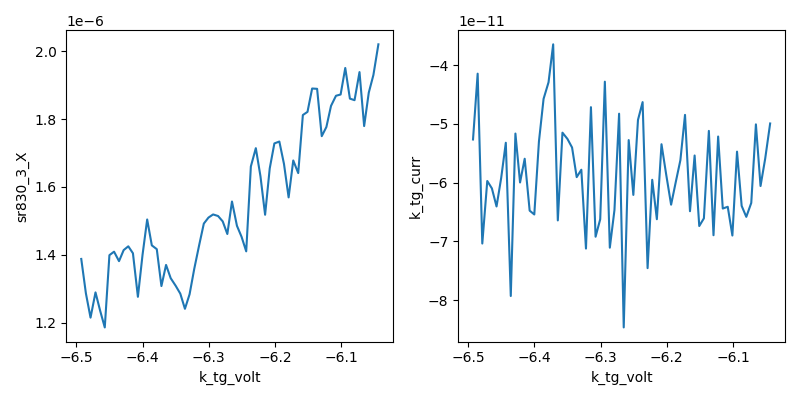

2026-06-24 18:39:22,686 [INFO] Completed in 0h 0m 48s


2026-06-24 18:39:22,686 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-3-zf1\data\5\data.tsv.gz


D=-0.60: 174/181 pts in-box  Vtg[-5.71,-4.47] Vbg[3.16,4.20]  n[-1.50,0.23]
2026-06-24 18:39:22,749 [INFO] Ramping k_tg_volt: -6.4925 -> -4.474599407067396


2026-06-24 18:39:25,385 [INFO] Ramping k_bg_volt: 3.8205 -> 4.1962313808270135


Sleeping:   0%|          | 0.0/5.0s []

2026-06-24 18:39:30,882 [INFO] Starting multisweep with ID 6


2026-06-24 18:39:30,883 [INFO] Minimum duration 0h 1m 44s


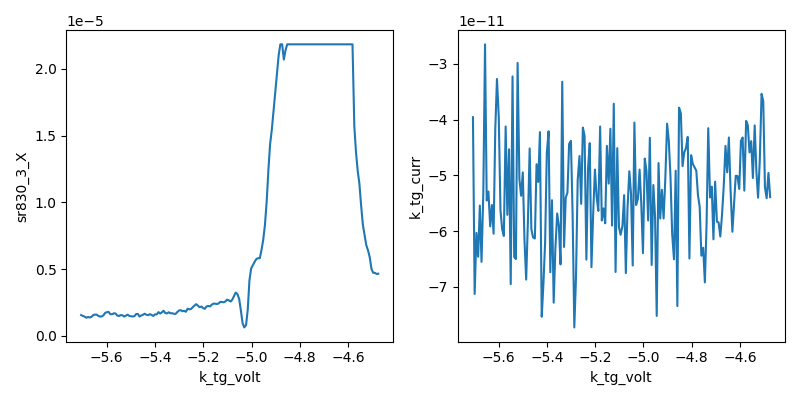

2026-06-24 18:41:43,959 [INFO] Completed in 0h 2m 12s


2026-06-24 18:41:43,959 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-3-zf1\data\6\data.tsv.gz


D=-0.50: 181/181 pts in-box  Vtg[-4.92,-3.64] Vbg[2.49,3.57]  n[-1.50,0.30]
2026-06-24 18:41:44,022 [INFO] Ramping k_tg_volt: -5.706 -> -3.638110820812545


2026-06-24 18:41:46,728 [INFO] Ramping k_bg_volt: 3.1555 -> 3.5735281381341353


Sleeping:   0%|          | 0.0/5.0s []

2026-06-24 18:41:52,269 [INFO] Starting multisweep with ID 7


2026-06-24 18:41:52,271 [INFO] Minimum duration 0h 1m 48s


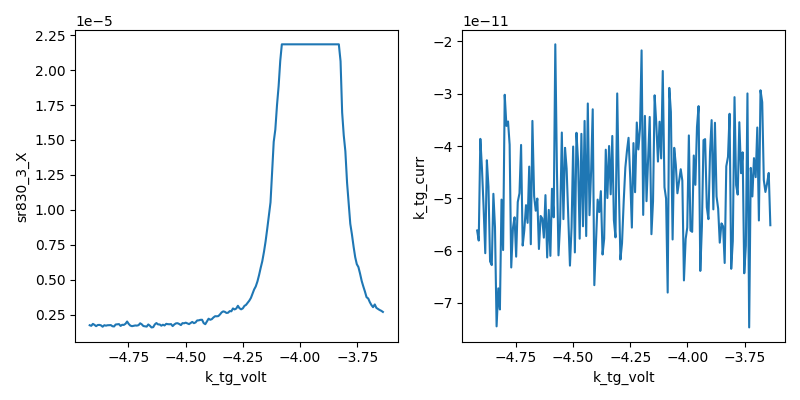

2026-06-24 18:44:10,270 [INFO] Completed in 0h 2m 17s


2026-06-24 18:44:10,271 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-3-zf1\data\7\data.tsv.gz


D=+0.50: 154/181 pts in-box  Vtg[3.14,4.23] Vbg[-3.99,-3.07]  n[-1.23,0.30]
2026-06-24 18:44:10,334 [INFO] Ramping k_tg_volt: -4.919 -> 4.228555845854122


2026-06-24 18:44:21,988 [INFO] Ramping k_bg_volt: 2.491 -> -3.0745464555163906


Sleeping:   0%|          | 0.0/5.0s []

2026-06-24 18:44:34,054 [INFO] Starting multisweep with ID 8


2026-06-24 18:44:34,054 [INFO] Minimum duration 0h 1m 32s


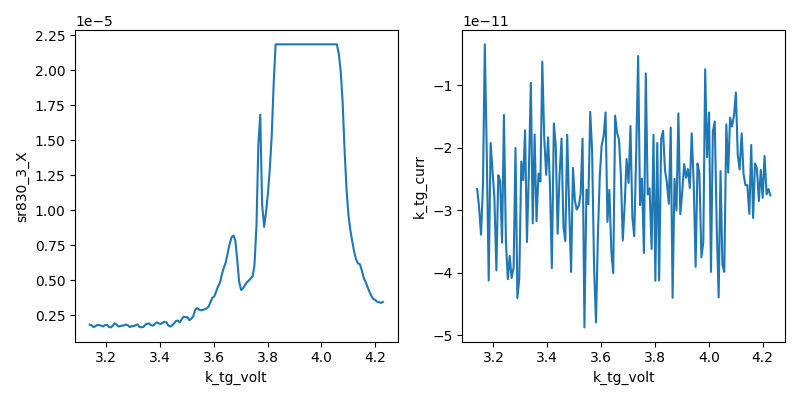

2026-06-24 18:46:31,533 [INFO] Completed in 0h 1m 57s


2026-06-24 18:46:31,534 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-3-zf1\data\8\data.tsv.gz


2026-06-24 18:46:31,595 [INFO] Ramping k_tg_volt: 3.1395 -> 0


2026-06-24 18:46:35,600 [INFO] Ramping k_bg_volt: -3.995 -> 0


In [16]:
# === Step 1 (locate): constant-D n-linecuts to find the SC arc ===
# sc-characterization Step 1 "locate with linecuts first": the coarse map
# (data/4) gave cap ratio 1.183 + overview but cannot resolve the ~5e10 cm^-2
# proximity-SC arc (sub-pixel at 0.16 V steps). Fine n-linecuts at fixed D
# scan for a low-Rxx dip. Prior: holes->WSe2 favours one D sign (|D|>~0.5),
# n ~ -0.4..-0.6 e12 cm^-2; scan WIDER than that, and cover BOTH D signs
# because the D-sign convention is not yet physically anchored (D_offset=0).
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

# --- preconditions (field still pristine; do NOT touch it) ---
print("T:", temperature(), "K  B:", magnet.field(), "T  gates:", k_tg.volt(), k_bg.volt())
assert temperature() < 0.060, "not at base T"
assert abs(magnet.field()) < 0.005, "field not near zero"

# calibration from data/4 CNP fit
c_tg = stack_capacitance([(23.6, 3)])
c_bg = c_tg * 1.1833                       # ratio data-calibrated (CNP slope)
n_off = -calc_nD(0.1634, 0.0, c_tg, c_bg)[0]   # CNP intercept -> n=0
print("c_tg=%.4e c_bg=%.4e n_off=%.4f" % (c_tg, c_bg, n_off))

# sensitivity: resolve a dip toward 0 across a ~0-200 ohm range (4T)
sr830_3.sensitivity(2e-5)                  # full-scale ~ 200 ohm at 1 nA, gain 100

n_vec = np.linspace(0.3, -1.5, 181)        # e12 cm^-2 (calc_nD units); wide of the -0.4..-0.6 prior
D_list = [-0.7, -0.6, -0.5, +0.5]          # V/nm; favoured (neg) side spans prior window + higher-n, +0.5 control

TG_MIN, TG_MAX = -7.0, 6.0
BG_MIN, BG_MAX = -4.0, 4.2

for D0 in D_list:
    Vtg, Vbg = calc_gate_voltages(n_vec, np.full_like(n_vec, D0), c_tg, c_bg, n_offset=n_off)
    inb = (Vtg >= TG_MIN) & (Vtg <= TG_MAX) & (Vbg >= BG_MIN) & (Vbg <= BG_MAX)
    vtg, vbg, nn = Vtg[inb], Vbg[inb], n_vec[inb]
    print("D=%+.2f: %d/%d pts in-box  Vtg[%.2f,%.2f] Vbg[%.2f,%.2f]  n[%.2f,%.2f]"
          % (D0, inb.sum(), len(n_vec), vtg.min(), vtg.max(), vbg.min(), vbg.max(), nn.min(), nn.max()))

    s = sweep.AsyncStation(meas_config)
    s.add_comment('cnp-and-dline-calibration')   # constant-D line designer (caps from CNP fit)
    s.add_comment(f'Step1 locate: constant-D n-linecut, D={D0:+.2f} V/nm')
    s.add_comment(f'n[{nn.min():+.2f},{nn.max():+.2f}] e12 cm^-2; caps ratio 1.183, n_off {n_off:.3f}, D_off 0')

    s.ramp(k_tg.volt, float(vtg[0]))
    s.ramp(k_bg.volt, float(vbg[0]))
    interruptable_sleep(5)

    s.fp(temperature)
    s.fp(k_tg.volt).fp(k_tg.curr)
    s.fp(k_bg.volt).fp(k_bg.curr)
    for lia in (sr830_1, sr830_2, sr830_3):
        s.fp(lia.X).fp(lia.P)
    s.plot(k_tg.volt, sr830_3.X)    # 4T Rxx vs the line
    s.plot(k_tg.volt, k_tg.curr)    # leakage

    s.multisweep([k_tg.volt, k_bg.volt], [vtg, vbg], delay=0.6)

# park gates (field untouched)
s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, 0)


## HERA — Step 2: bias spectroscopy at the candidate (decisive SC test)

dV/dI vs I_dc at the Step-1 candidate **n=−0.55×10¹² cm⁻², D=−0.60 V/nm** (Vtg=−5.03, Vbg=3.73 — the ±D-asymmetric 4T Rxx dip to ~6 Ω). This is the decisive hallmark per sc-characterization Step 2: a supercurrent shows dV/dI≈0 for |I_dc|<Ic, rising at a critical current.

**Sweep:** DC bias via dc205_1 / 100 MΩ → **±150 nA** (±15 V, the reachable max; brackets the ~20 nA reference Ic by 7.5×), **round-trip** (121+121 pts) to catch hysteresis, delay 1.5 s (5×TC). AC excitation 1 nA; 4T sens 2×10⁻⁵ (resolves SC near-zero and a switching peak up to ~200 Ω). Crossing I_dc=0 is required (this is bias current, not field — field stays pristine/untouched). DC parked to 0 after.

**Read:** a low-dV/dI plateau near zero bias terminating in switching peaks at ±Ic = supercurrent (strong SC). Flat/ohmic dV/dI = normal metal (→ then I tighten-map for a better optimum before any not-SC lean — no over-read of one point). ~7 min. Running autonomously (E1).

In [17]:
# === Step 2: bias spectroscopy (dV/dI vs I_dc) at the candidate ===
# sc-characterization Step 2 / bias-spectroscopy point-check. Decisive SC test:
# dV/dI ~ 0 for |I_dc| < Ic, rising at a critical current = supercurrent.
# Candidate from Step-1 linecuts: n=-0.55e12 cm^-2, D=-0.60 V/nm (Vtg=-5.03,
# Vbg=3.73) — the +/-D-asymmetric Rxx dip to ~6 ohm.
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

# --- preconditions (field pristine; DC bias starts from 0) ---
print("T:", temperature(), "B:", magnet.field(), "gates:", k_tg.volt(), k_bg.volt(),
      "dc205_1:", dc205_1.volt())
assert temperature() < 0.060, "not at base T"
assert abs(magnet.field()) < 0.005, "field not near zero"
assert abs(dc205_1.volt()) < 1e-6, "DC bias not at 0"

c_tg = stack_capacitance([(23.6,3)]); c_bg = c_tg*1.1833
n_off = -calc_nD(0.1634,0.0,c_tg,c_bg)[0]
Vtg_op, Vbg_op = [float(x) for x in calc_gate_voltages([-0.55],[-0.6],c_tg,c_bg,n_offset=n_off)]
print("operating point: Vtg=%.3f Vbg=%.3f" % (Vtg_op, Vbg_op))

# AC excitation 1 nA (0.1 V / 100 MOhm); DC bias via dc205_1 / 100 MOhm: +/-15 V -> +/-150 nA
sr830_1.amplitude(0.1)
sr830_3.sensitivity(2e-5)              # dV/dI up to ~200 ohm @1nA, gain 100; resolves SC near-zero
R_BIAS = 1e8

# round-trip bias sweep, symmetric across 0 (must cross I_dc=0 — this is current, not field)
fwd = np.linspace(-15, 15, 121)
bwd = np.linspace(15, -15, 121)
Vdc = np.hstack((fwd, bwd))             # I_dc = Vdc / R_BIAS -> +/-150 nA

s = sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy')
s.add_comment('Step2 point-check at candidate n=-0.55e12 cm^-2, D=-0.60 V/nm')
s.add_comment(f'Vtg={Vtg_op:.3f} Vbg={Vbg_op:.3f}; Idc +/-150 nA (Vdc +/-15 V / 100 MOhm); AC 1 nA; round-trip')

# ramp gates to the operating point, settle
s.ramp(k_tg.volt, Vtg_op)
s.ramp(k_bg.volt, Vbg_op)
interruptable_sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(dc205_1.volt, sr830_3.X)        # dV/dI (4T) vs DC bias
s.plot(dc205_1.volt, sr830_1.X)        # AC current monitor

s.sweep(dc205_1.volt, Vdc, delay=1.5)  # 5 x TC settle

# park DC bias to 0 first (device card), then gates
s.ramp(dc205_1.volt, 0)
s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, 0)


T: 0.03413 B: -2.0975e-05 gates: 0.0 0.0 dc205_1: 0.0


TypeError: unsupported operand type(s) for -: 'list' and 'float'

### HERA — bias-spec (corrected: np.array args to calc_gate_voltages)
Prior cell hit a TypeError (lists, not arrays) at the gate-voltage calc — before any hardware move. Same measurement, fixed.

In [18]:
# === Step 2: bias spectroscopy (dV/dI vs I_dc) at the candidate ===
# sc-characterization Step 2 / bias-spectroscopy point-check. Decisive SC test:
# dV/dI ~ 0 for |I_dc| < Ic, rising at a critical current = supercurrent.
# Candidate from Step-1 linecuts: n=-0.55e12 cm^-2, D=-0.60 V/nm (Vtg=-5.03,
# Vbg=3.73) — the +/-D-asymmetric Rxx dip to ~6 ohm.
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

# --- preconditions (field pristine; DC bias starts from 0) ---
print("T:", temperature(), "B:", magnet.field(), "gates:", k_tg.volt(), k_bg.volt(),
      "dc205_1:", dc205_1.volt())
assert temperature() < 0.060, "not at base T"
assert abs(magnet.field()) < 0.005, "field not near zero"
assert abs(dc205_1.volt()) < 1e-6, "DC bias not at 0"

c_tg = stack_capacitance([(23.6,3)]); c_bg = c_tg*1.1833
n_off = -calc_nD(0.1634,0.0,c_tg,c_bg)[0]
Vtg_op, Vbg_op = [float(x) for x in calc_gate_voltages(np.array([-0.55]),np.array([-0.6]),c_tg,c_bg,n_offset=n_off)]
print("operating point: Vtg=%.3f Vbg=%.3f" % (Vtg_op, Vbg_op))

# AC excitation 1 nA (0.1 V / 100 MOhm); DC bias via dc205_1 / 100 MOhm: +/-15 V -> +/-150 nA
sr830_1.amplitude(0.1)
sr830_3.sensitivity(2e-5)              # dV/dI up to ~200 ohm @1nA, gain 100; resolves SC near-zero
R_BIAS = 1e8

# round-trip bias sweep, symmetric across 0 (must cross I_dc=0 — this is current, not field)
fwd = np.linspace(-15, 15, 121)
bwd = np.linspace(15, -15, 121)
Vdc = np.hstack((fwd, bwd))             # I_dc = Vdc / R_BIAS -> +/-150 nA

s = sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy')
s.add_comment('Step2 point-check at candidate n=-0.55e12 cm^-2, D=-0.60 V/nm')
s.add_comment(f'Vtg={Vtg_op:.3f} Vbg={Vbg_op:.3f}; Idc +/-150 nA (Vdc +/-15 V / 100 MOhm); AC 1 nA; round-trip')

# ramp gates to the operating point, settle
s.ramp(k_tg.volt, Vtg_op)
s.ramp(k_bg.volt, Vbg_op)
interruptable_sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(dc205_1.volt, sr830_3.X)        # dV/dI (4T) vs DC bias
s.plot(dc205_1.volt, sr830_1.X)        # AC current monitor

s.sweep(dc205_1.volt, Vdc, delay=1.5)  # 5 x TC settle

# park DC bias to 0 first (device card), then gates
s.ramp(dc205_1.volt, 0)
s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, 0)


T: 0.03413 B: -1.3026e-05 gates: 0.0 0.0 dc205_1: 0.0


TypeError: only 0-dimensional arrays can be converted to Python scalars

### HERA — bias-spec (corrected v2: scalar extraction; tested offline)
Same measurement; gate-voltage calc now extracts scalars from the (1,)-arrays (verified offline). Hardware never moved on the two prior attempts (errors before any ramp).

T: 0.03434 B: 1.3689e-05 gates: 0.0 0.0 dc205_1: 0.0
operating point: Vtg=-5.030 Vbg=3.727


2026-06-24 20:23:00,493 [INFO] Ramping k_tg_volt: 0.0 -> -5.0297579396214465


2026-06-24 20:23:06,973 [INFO] Ramping k_bg_volt: 0.0 -> 3.7270701093370704


Sleeping:   0%|          | 0.0/10.0s []

2026-06-24 20:23:21,652 [INFO] Starting sweep with ID 12


2026-06-24 20:23:21,653 [INFO] Minimum duration 0h 6m 3s


2026-06-24 20:23:40,064 [WARNING] ID 12 INTERRUPTED


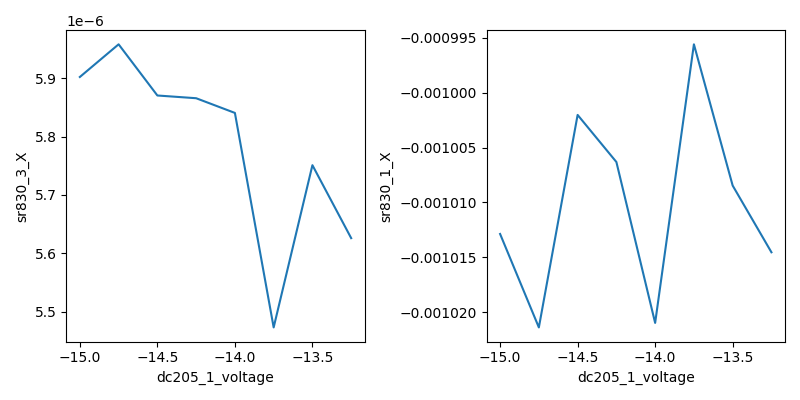

2026-06-24 20:23:40,460 [INFO] Completed in 0h 0m 18s


2026-06-24 20:23:40,461 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-3-zf1\data\12\data.tsv.gz


2026-06-24 20:23:40,473 [INFO] Ramping dc205_1_voltage: -13.25 -> 0


2026-06-24 20:23:44,677 [INFO] Ramping k_tg_volt: -5.03 -> 0


2026-06-24 20:23:51,323 [INFO] Ramping k_bg_volt: 3.727 -> 0


In [24]:
# === Step 2: bias spectroscopy (dV/dI vs I_dc) at the candidate ===
# sc-characterization Step 2 / bias-spectroscopy point-check. Decisive SC test:
# dV/dI ~ 0 for |I_dc| < Ic, rising at a critical current = supercurrent.
# Candidate from Step-1 linecuts: n=-0.55e12 cm^-2, D=-0.60 V/nm (Vtg=-5.03,
# Vbg=3.73) — the +/-D-asymmetric Rxx dip to ~6 ohm.
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

# --- preconditions (field pristine; DC bias starts from 0) ---
print("T:", temperature(), "B:", magnet.field(), "gates:", k_tg.volt(), k_bg.volt(),
      "dc205_1:", dc205_1.volt())
assert temperature() < 0.060, "not at base T"
assert abs(magnet.field()) < 0.005, "field not near zero"
assert abs(dc205_1.volt()) < 1e-6, "DC bias not at 0"

c_tg = stack_capacitance([(23.6,3)]); c_bg = c_tg*1.1833
n_off = -calc_nD(0.1634,0.0,c_tg,c_bg)[0]
Vtg_arr, Vbg_arr = calc_gate_voltages(np.array([-0.55]), np.array([-0.6]), c_tg, c_bg, n_offset=n_off)
Vtg_op, Vbg_op = float(Vtg_arr[0]), float(Vbg_arr[0])
print("operating point: Vtg=%.3f Vbg=%.3f" % (Vtg_op, Vbg_op))

# AC excitation 1 nA (0.1 V / 100 MOhm); DC bias via dc205_1 / 100 MOhm: +/-15 V -> +/-150 nA
sr830_1.amplitude(0.1)
sr830_3.sensitivity(2e-5)              # dV/dI up to ~200 ohm @1nA, gain 100; resolves SC near-zero
R_BIAS = 1e8

# round-trip bias sweep, symmetric across 0 (must cross I_dc=0 — this is current, not field)
fwd = np.linspace(-15, 15, 121)
bwd = np.linspace(15, -15, 121)
Vdc = np.hstack((fwd, bwd))             # I_dc = Vdc / R_BIAS -> +/-150 nA

s = sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy')
s.add_comment('Step2 point-check at candidate n=-0.55e12 cm^-2, D=-0.60 V/nm')
s.add_comment(f'Vtg={Vtg_op:.3f} Vbg={Vbg_op:.3f}; Idc +/-150 nA (Vdc +/-15 V / 100 MOhm); AC 1 nA; round-trip')

# ramp gates to the operating point, settle
s.ramp(k_tg.volt, Vtg_op)
s.ramp(k_bg.volt, Vbg_op)
interruptable_sleep(10)

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(dc205_1.volt)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(dc205_1.volt, sr830_3.X)        # dV/dI (4T) vs DC bias
s.plot(dc205_1.volt, sr830_1.X)        # AC current monitor

s.sweep(dc205_1.volt, Vdc, delay=1.5)  # 5 x TC settle

# park DC bias to 0 first (device card), then gates
s.ramp(dc205_1.volt, 0)
s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, 0)


## HERA — magnet status check (pre field-response)
Read-only: ramp rate + current field, to price the first ramp and size the post-ramp settle before the Step-3 field-kill.

In [20]:
print('field [T]:', magnet.field())
print('ramp_rate [T/s]:', magnet.ramp_rate())
print('field validator:', magnet.field.vals)
print('T:', temperature(), 'K')

field [T]: -1.766e-06
ramp_rate [T/s]: 0.001
field validator: <Numbers -0.1<=v<=0.1>
T: 0.03414 K


## HERA — Step 3: field-kill (Rxx vs B⊥) at the candidate

**First magnet move of the session** — ends the pristine-field era. Tests the decisive corroborator: does a small B⊥ quench the zero-bias dip (the SC) while the normal state stays put? Rxx(B) at n=−0.55×10¹², D=−0.6 V/nm, **zero DC bias**, AC 1 nA.

**Field discipline (brief):** position the magnet at **+50 mT** (within the 100 mT cap), settle ~2 min (first ramp; I print T to confirm recovery), then sweep **one-sided down to 0** (101 pts, 0.5 mT) — never increasing |B| through 0. Ramp rate 1 mT/s.

**Read:** if Rxx rises from ~7 Ω (near 0) to the ~50 Ω normal state over a few–tens of mT, that's field-killing of the supercurrent → strong SC corroboration; B_c⊥ ≈ the half-recovery field. A flat/ohmic Rxx(B) would argue against SC. fp(temperature) guards against ramp-heating artifacts near 0. ~6–7 min. E1.

T: 0.03421 B: -1.7884e-05 gates: 0.0 0.0 dc205_1: 0.0
operating point: Vtg=-5.030 Vbg=3.727
2026-06-24 19:58:07,068 [INFO] Ramping dc205_1_voltage: 0.0 -> 0


2026-06-24 19:58:07,130 [INFO] Ramping k_tg_volt: 0.0 -> -5.0297579396214465


2026-06-24 19:58:13,602 [INFO] Ramping k_bg_volt: 0.0 -> 3.7270701093370704


2026-06-24 19:58:18,301 [INFO] Ramping magnet_field: 4.195e-06 -> 0.05


Sleeping:   0%|          | 0.0/120.0s []

after settle: T = 0.03496 K  B = 0.050010319 T
2026-06-24 20:01:18,174 [INFO] Starting sweep with ID 10


2026-06-24 20:01:18,175 [INFO] Minimum duration 0h 1m 41s


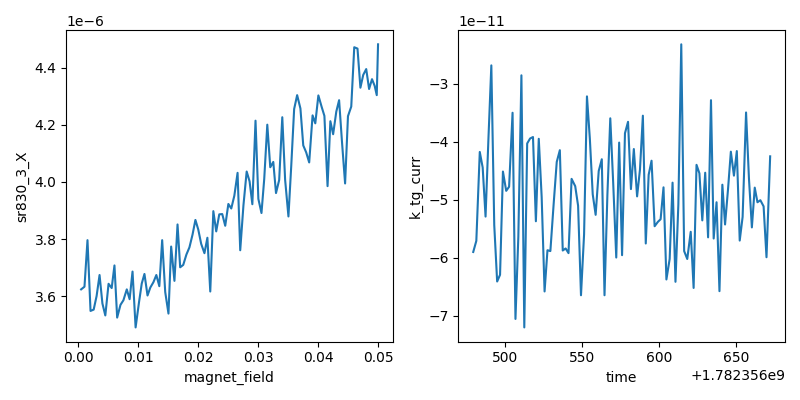

2026-06-24 20:04:32,830 [INFO] Completed in 0h 3m 14s


2026-06-24 20:04:32,830 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-3-zf1\data\10\data.tsv.gz


2026-06-24 20:04:32,892 [INFO] Ramping k_tg_volt: -5.03 -> 0


2026-06-24 20:04:39,372 [INFO] Ramping k_bg_volt: 3.727 -> 0


In [21]:
# === Step 3: field response (B_perp field-kill) at the candidate ===
# sc-characterization Step 3: does a small B_perp quench the zero-bias dip while
# the normal state stays ~unchanged? Rxx(B) at n=-0.55e12 cm^-2, D=-0.60 V/nm,
# ZERO DC bias, AC 1 nA. FIRST magnet move of the session (ends pristine era).
# Field discipline (brief): position at +|B|max, settle, sweep one-sided DOWN to
# 0 — never increase |B| through 0 in a measurement.
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

# --- preconditions ---
print("T:", temperature(), "B:", magnet.field(), "gates:", k_tg.volt(), k_bg.volt(),
      "dc205_1:", dc205_1.volt())
assert temperature() < 0.060, "not at base T"
assert abs(dc205_1.volt()) < 1e-6, "DC bias not at 0"

c_tg = stack_capacitance([(23.6,3)]); c_bg = c_tg*1.1833
n_off = -calc_nD(0.1634,0.0,c_tg,c_bg)[0]
Vtg_arr, Vbg_arr = calc_gate_voltages(np.array([-0.55]), np.array([-0.6]), c_tg, c_bg, n_offset=n_off)
Vtg_op, Vbg_op = float(Vtg_arr[0]), float(Vbg_arr[0])
print("operating point: Vtg=%.3f Vbg=%.3f" % (Vtg_op, Vbg_op))

sr830_1.amplitude(0.1)            # AC 1 nA
sr830_3.sensitivity(2e-5)         # dV/dI up to ~200 ohm; resolves dip (~7) -> normal (~50)
B_MAX = 0.05                      # T (50 mT; well within 100 mT cap)

s = sweep.AsyncStation(meas_config)
s.add_comment('field-sweep-1d')
s.add_comment('Step3 field-kill at candidate n=-0.55e12 cm^-2, D=-0.60 V/nm (zero DC bias)')
s.add_comment(f'(Vtg, Vbg) = ({Vtg_op:.3f}, {Vbg_op:.3f}); B {B_MAX*1e3:.0f} mT -> 0, one-sided toward 0; AC 1 nA')

# position: gates to candidate, DC bias 0, then magnet UP to +B_MAX
s.ramp(dc205_1.volt, 0)
s.ramp(k_tg.volt, Vtg_op)
s.ramp(k_bg.volt, Vbg_op)
s.ramp(magnet.field, B_MAX)       # 0 -> +50 mT at 1 mT/s (~50 s)
interruptable_sleep(120)          # first-ramp thermal settle
print("after settle: T =", temperature(), "K  B =", magnet.field(), "T")

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(magnet.field)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(magnet.field, sr830_3.X)   # Rxx vs B (the field-kill trace)
s.plot('time', k_tg.curr)         # leakage

# one-sided sweep DOWN to 0 (toward zero), fine steps
s.sweep(magnet.field, np.linspace(B_MAX, 0.0, 101), delay=1)

# park: magnet already at 0; gates to 0
s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, 0)


## HERA — Step 3 (cont): field-kill PASS B (negative-controller side → effective zero)

Pass A (data/10) showed only the dip's high-field shoulder (Rxx 43→36 Ω, no dip at controller-0): the 50 mT excursion left ~10 mT remanence (rig card: set by energizing, **not** flipped by direction reversal), so true B=0 — the SC's field maximum — is at **negative controller field** (Rxx was still declining at 0, and a +controller dip would have shown in pass A). This is the investigation's effective-zero subtlety.

**Pass B:** position at **−50 mT**, settle ~2 min, sweep one-sided up to 0 (101 pts) — crosses true-zero (~controller −8 mT) to reveal the ~7 Ω dip flanked by rising Rxx (the field-kill mirror). Still zero DC bias, AC 1 nA, T-guarded. Does not cross 0 in the measurement. ~6–7 min. E1.

T: 0.03458 B: 4.416e-06 gates: 0.0 0.0 dc205_1: 0.0
2026-06-24 20:07:30,947 [INFO] Ramping dc205_1_voltage: 0.0 -> 0


2026-06-24 20:07:31,008 [INFO] Ramping k_tg_volt: 0.0 -> -5.0297579396214465


2026-06-24 20:07:37,491 [INFO] Ramping k_bg_volt: 0.0 -> 3.7270701093370704


2026-06-24 20:07:42,334 [INFO] Ramping magnet_field: -3.1352e-05 -> -0.05


Sleeping:   0%|          | 0.0/120.0s []

after settle: T = 0.03525 K  B = -0.049987136 T
2026-06-24 20:10:42,443 [INFO] Starting sweep with ID 11


2026-06-24 20:10:42,443 [INFO] Minimum duration 0h 1m 41s


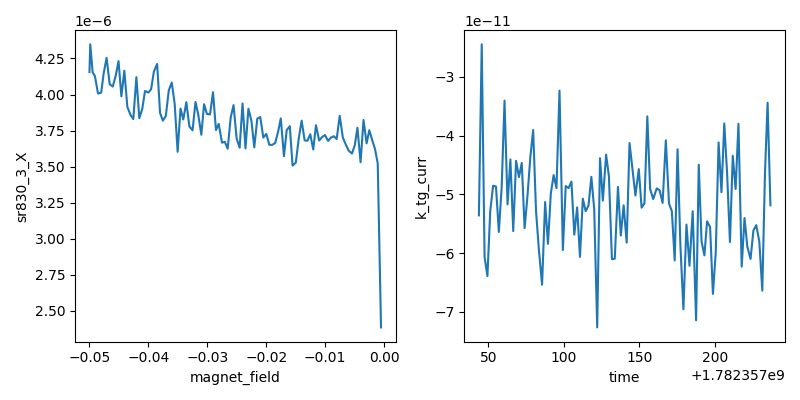

2026-06-24 20:13:57,256 [INFO] Completed in 0h 3m 14s


2026-06-24 20:13:57,257 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260624-3-zf1\data\11\data.tsv.gz


2026-06-24 20:13:57,323 [INFO] Ramping k_tg_volt: -5.03 -> 0


2026-06-24 20:14:03,802 [INFO] Ramping k_bg_volt: 3.727 -> 0


In [22]:
# === Step 3 (cont): field-kill PASS B — negative-controller side ===
# Pass A (+50->0) showed only the high-field shoulder: Rxx 43->36 ohm, no dip at
# controller-0. The 50 mT excursion left ~10 mT remanence (rig card: set by going
# to finite field, NOT flipped by direction reversal), so TRUE B=0 (the SC's field
# maximum) is at NEGATIVE controller field. This pass crosses it: position at
# -50 mT, settle, sweep one-sided UP to 0. Expect the ~7 ohm dip near controller
# ~-8 mT = effective zero, with Rxx rising on both sides (the field-kill).
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

print("T:", temperature(), "B:", magnet.field(), "gates:", k_tg.volt(), k_bg.volt(),
      "dc205_1:", dc205_1.volt())
assert temperature() < 0.060, "not at base T"
assert abs(dc205_1.volt()) < 1e-6, "DC bias not at 0"

c_tg = stack_capacitance([(23.6,3)]); c_bg = c_tg*1.1833
n_off = -calc_nD(0.1634,0.0,c_tg,c_bg)[0]
Vtg_arr, Vbg_arr = calc_gate_voltages(np.array([-0.55]), np.array([-0.6]), c_tg, c_bg, n_offset=n_off)
Vtg_op, Vbg_op = float(Vtg_arr[0]), float(Vbg_arr[0])

sr830_1.amplitude(0.1)
sr830_3.sensitivity(2e-5)
B_MIN = -0.05                       # T (-50 mT)

s = sweep.AsyncStation(meas_config)
s.add_comment('field-sweep-1d')
s.add_comment('Step3 field-kill PASS B (neg side) at candidate n=-0.55, D=-0.60 (zero DC bias)')
s.add_comment(f'(Vtg, Vbg) = ({Vtg_op:.3f}, {Vbg_op:.3f}); B {B_MIN*1e3:.0f} mT -> 0, one-sided toward 0; locate effective zero')

s.ramp(dc205_1.volt, 0)
s.ramp(k_tg.volt, Vtg_op)
s.ramp(k_bg.volt, Vbg_op)
s.ramp(magnet.field, B_MIN)        # 0 -> -50 mT (~50 s); does not cross 0
interruptable_sleep(120)
print("after settle: T =", temperature(), "K  B =", magnet.field(), "T")

s.fp(temperature)
s.fp(k_tg.volt).fp(k_tg.curr)
s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(magnet.field)
for lia in (sr830_1, sr830_2, sr830_3):
    s.fp(lia.X).fp(lia.P)
s.plot(magnet.field, sr830_3.X)
s.plot('time', k_tg.curr)

s.sweep(magnet.field, np.linspace(B_MIN, 0.0, 101), delay=1)   # -50 -> 0, toward zero

s.ramp(k_tg.volt, 0)
s.ramp(k_bg.volt, 0)


## HERA — session pause: device parked, verdict delivered

Base-T + field characterization complete. Candidate C1 (n=−0.55×10¹², D=−0.60 V/nm) = **consistent-with superconductivity, compelling proximity-SC candidate** (4 hallmarks: Rxx dip, critical current Ic≈15 nA, ±D asymmetry, field-kill). Full 5-part call in the ana notebook. Step-4 T-dependence (the decisive Ic-collapse) deferred — it is a ~3 h heat-up that ends base-T work and should follow a magnet re-zero (the field-char left ~10 mT remanence off the SC optimum).

In [23]:
# Read-only: confirm safe parked state
print('gates:', k_tg.volt(), k_bg.volt(), 'V')
print('dc205_1:', dc205_1.volt(), 'V')
print('magnet:', magnet.field(), 'T')
print('T:', temperature(), 'K')
print('AC amp:', sr830_1.amplitude(), 'V')

gates: 0.0 0.0 V
dc205_1: 0.0 V
magnet: 1.987e-06 T
T: 0.03443 K
AC amp: 0.1 V


## HERA — ABORT: operator called the session. Safe-park.
Interrupt landed mid bias-spec sweep (its park runs after the sweep, so gates/DC bias were left at the operating point). This reads state, ramps DC bias→0 (device card), then gates→0, and verifies. Magnet already at ~0.

In [25]:
print('pre-park: gates', k_tg.volt(), k_bg.volt(), '| dc205_1', dc205_1.volt(), '| B', magnet.field(), '| T', temperature())
dc205_1.volt(0)          # DC bias -> 0 FIRST (device card); substeps at volt.step
k_tg.volt(0)             # substeps at 5 mV
k_bg.volt(0)
print('post-park: gates', k_tg.volt(), k_bg.volt(), '| dc205_1', dc205_1.volt(), '| B', magnet.field(), '| T', temperature())

pre-park: gates 0.0 0.0 | dc205_1 0.0 | B 4.4599e-05 | T 0.03428


post-park: gates 0.0 0.0 | dc205_1 0.0 | B -2.4728e-05 | T 0.03428
